# 04 · The minutes model

**Why first?** Around half of all FPL points are appearance points (notebook 00), and nothing else counts if a player
doesn't play. Clean sheets also need **60+ minutes**. So for every player-fixture we predict three probabilities:

| Outcome | FPL meaning |
|---|---|
| `p0`: doesn't play | 0 points |
| `p_1_59`: plays 1–59 min | 1 appearance point, no clean sheet |
| `p_60`: plays 60+ | 2 appearance points, clean sheet eligible |

…and **expected minutes** from those probabilities. The model is **LightGBM**: hundreds of small decision trees, each
correcting the previous ones' mistakes. It's good at "if he started the last 3 but was benched last week, and he's a
new signing…" patterns.

Code: [`fpl_engine/models/minutes.py`](../fpl_engine/models/minutes.py)

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import log_loss
from fpl_engine import db, backtest
from fpl_engine.features import load_base, build_features
from fpl_engine.models.minutes import MinutesModel, LookupMinutes, minutes_class, apply_availability, FEATURES
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 200)
with db.connect() as conn:
    base = load_base(conn)
f = build_features(base)
preds = backtest.run(f, [MinutesModel(), LookupMinutes()]).dropna(subset=['y_minutes'])
preds['cls'] = minutes_class(preds.y_minutes)
print(f"{preds.gw_key.nunique()} gameweeks backtested (2024-25 →), retrained every 5")

87 gameweeks backtested (2024-25 →), retrained every 5


## 1 · Does it beat the simple lookup?

**Baseline** (`minutes_lookup`): "players who started *s* and appeared in *a* of their last 5 went on to play X% of the
time". That's the table from notebook 00, learned from training data.

Metrics (all *lower is better*):
- **log loss**: penalises confident wrong predictions heavily (saying 95% he plays when he doesn't).
- **Brier**: squared error of a probability, for "plays at all" and "plays 60+".
- **expected-minutes MAE**: how far expected minutes are from actual minutes.

In [2]:
def score(d):
    y = d.cls
    return pd.Series({'log loss': log_loss(y, d[['p0', 'p_1_59', 'p_60']].to_numpy(), labels=[0, 1, 2]),
                      'Brier: plays': ((d.p_plays - (d.y_minutes > 0)) ** 2).mean(),
                      'Brier: 60+': ((d.p_60 - (d.y_minutes >= 60)) ** 2).mean(),
                      'xmins MAE': (d.xmins - d.y_minutes).abs().mean()})
res = pd.concat({'rotation-relevant': preds[preds.rotation_relevant].groupby('model').apply(score),
                 'all squad players': preds.groupby('model').apply(score)})
res.round(4)

log loss  Brier: plays  Brier: 60+  xmins MAE
                  model                                                        
rotation-relevant minutes_lgbm      0.7413        0.1249      0.1592    23.6705
                  minutes_lookup    0.8213        0.1433      0.1848    27.5922
all squad players minutes_lgbm      0.4849        0.0928      0.0860    13.7767
                  minutes_lookup    0.5587        0.1103      0.1023    16.5290

## 2 · Calibration: when it says 70%, does it happen 70% of the time?

A **reliability curve** groups predictions into bins and plots the predicted probability against how often it actually
happened. A perfectly calibrated model sits on the diagonal. Calibration matters because these probabilities get
**multiplied** into every other component (goals, clean sheets…).

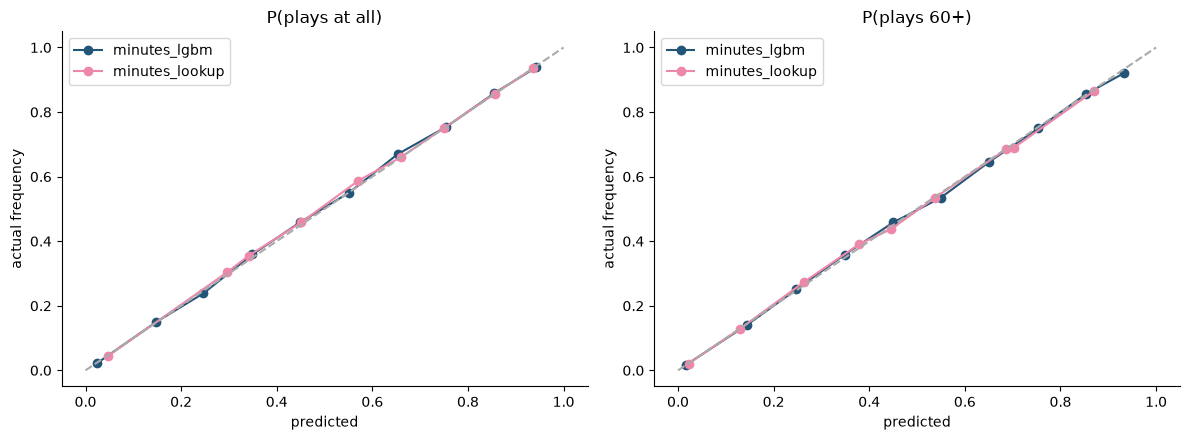

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (col, outcome, title) in zip(axes, [('p_plays', preds.y_minutes > 0, 'P(plays at all)'),
                                             ('p_60', preds.y_minutes >= 60, 'P(plays 60+)')]):
    for m, color in [('minutes_lgbm', '#257'), ('minutes_lookup', '#e8a')]:
        d = preds[preds.model == m]
        o = outcome[d.index]
        bins = pd.cut(d[col], np.linspace(0, 1, 11), include_lowest=True)
        cal = pd.DataFrame({'pred': d[col], 'actual': o.astype(float), 'bin': bins}).groupby('bin', observed=True).mean()
        ax.plot(cal.pred, cal.actual, marker='o', color=color, label=m)
    ax.plot([0, 1], [0, 1], '--', color='#aaa'); ax.set_title(title); ax.set_xlabel('predicted'); ax.set_ylabel('actual frequency')
    ax.legend()
plt.tight_layout(); plt.show()

## 3 · What does the model rely on?

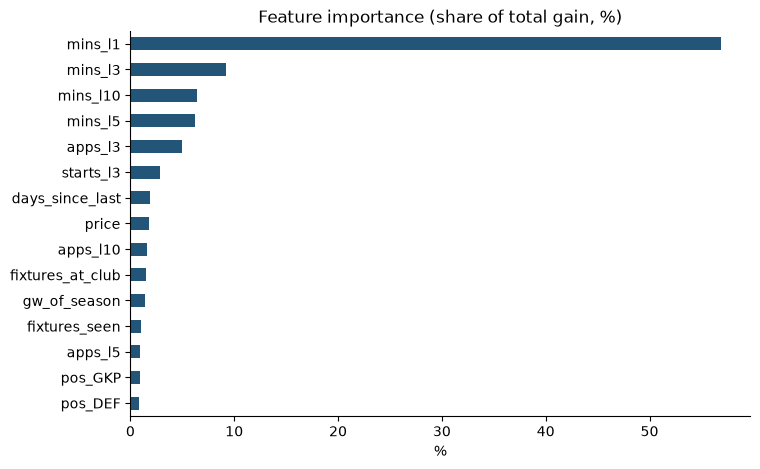

In [4]:
latest = MinutesModel()
latest.fit(f[(f.season >= '2022-23')].dropna(subset=['y_minutes']))
imp = pd.Series(latest.clf.booster_.feature_importance('gain'), index=latest.features)
(imp / imp.sum() * 100).sort_values().tail(15).plot.barh(color='#257', figsize=(8, 5))
plt.title('Feature importance (share of total gain, %)'); plt.xlabel('%'); plt.show()

Recent minutes and starts dominate, as expected. Price (a proxy for how important the player is to the club) and
time-at-club (new signings settle in) add context.

## 4 · Where it fails: the nailed-on starter who doesn't play

In [5]:
rr = preds[(preds.model == 'minutes_lgbm') & preds.rotation_relevant]
nailed = rr[rr.p_plays >= 0.9]
miss = nailed[nailed.y_minutes == 0]
print(f"Predicted ≥90% to play: {len(nailed):,} player-fixtures; actually didn't play: {len(miss):,} ({len(miss)/len(nailed):.1%})")
print(f"Average predicted P(plays) for that group: {nailed.p_plays.mean():.1%} → actual {(nailed.y_minutes > 0).mean():.1%}")

Predicted ≥90% to play: 11,757 player-fixtures; actually didn't play: 729 (6.2%)
Average predicted P(plays) for that group: 94.2% → actual 93.8%


Even "certain" starters miss about 1 in 20 games, almost always through a **late injury, illness or suspension**
the model can't see in playing-time history. That's what the **availability overlay** fixes for live predictions:
FPL's `chance_of_playing` and status flags (injured / suspended / doubtful) cap P(plays).

We can't backtest the overlay (there's no availability history before this season; we now record it every 6 hours),
but here's what it does:

In [6]:
demo = pd.DataFrame({'p0': [0.05, 0.05, 0.05], 'p_1_59': [0.10, 0.10, 0.10], 'p_60': [0.85, 0.85, 0.85],
                     'xmins': [80.0, 80.0, 80.0], 'p_plays': [0.95, 0.95, 0.95]},
                    index=['no flag', '75% chance (doubtful)', 'injured'])
apply_availability(demo, pd.Series([np.nan, 75, 0], index=demo.index), pd.Series(['a', 'd', 'i'], index=demo.index)).round(3)

,p0,p_1_59,p_60,xmins,p_plays
no flag,0.05,0.100,0.850,80.000,0.95
75% chance (doubtful),0.25,0.079,0.671,63.158,0.75
injured,1.00,0.000,0.000,0.000,0.00


## 5 · How minutes feed into points
Every later component is conditioned on these probabilities. For example, a defender's clean-sheet contribution is
`P(60+) × P(team keeps a clean sheet) × 4 points`, and his appearance points are `1 × P(1–59) + 2 × P(60+)`.

---
## ✅ Decisions (made with you, 2026-11-23)
1. **The LightGBM minutes model is the minutes component.**
2. **Cup & European minutes: tracked follow-up, potentially important.** Once the full model works end to end, load
   non-Premier-League fixtures from PitchAPI and measure how minutes in a midweek cup/European match relate to minutes
   in the *following* PL match (a rotation player rested, or injured, midweek). Add it as a feature if it helps.
3. **Availability overlay agreed:** FPL chance-of-playing caps P(plays); injured / suspended / unavailable → 0.